# picomake - activations_gradients

In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import math
%matplotlib inline

In [2]:
words = open("names.txt", "r").read().split()
words[:3]

# build vocabulary

stoi = {}
stoi['.'] = 0
vocab = sorted(list(set(letters for word in words for letters in word)))
for i, ch in enumerate(vocab, start = 1):
    stoi[ch] = i
stoi

{'.': 0,
 'a': 1,
 'b': 2,
 'c': 3,
 'd': 4,
 'e': 5,
 'f': 6,
 'g': 7,
 'h': 8,
 'i': 9,
 'j': 10,
 'k': 11,
 'l': 12,
 'm': 13,
 'n': 14,
 'o': 15,
 'p': 16,
 'q': 17,
 'r': 18,
 's': 19,
 't': 20,
 'u': 21,
 'v': 22,
 'w': 23,
 'x': 24,
 'y': 25,
 'z': 26}

In [3]:
# build out dataset
def build_dataset(words):
    context_size = 3
    X = []
    Y = []

    for w in words:
        context = [0]*context_size

        for i in w+'.':
            ix = stoi[i]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context [1:] + [ix]


    X = torch.tensor(X) # X stores the context of one training example in chunk of context size (stoi)
    Y = torch.tensor(Y) # Y stores the stoi value of each char in the word
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

# let us create an embedding matrix where every character 
# gets a 2 dimensional embedding using the awesome pytorch indexing
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27,2), generator=g)
emb = C[Xtr] # torch.Size([182625, 3, 2])

### Neural Network Tensor Shapes

- **Input (`Xtr`):** `(182625, 3)` — 182,625 examples, each containing 3 character indices.
- **Embedding matrix (`C`):** `(27, 10)` — 27 characters, each represented by a 10-dimensional vector.
- **Embedding lookup (`C[Xtr[ix]]`):** `(64, 3, 10)` — 64 examples × 3 characters × 10 embedding dimensions. The full dataset produces `(182625, 3, 10)`.

**Hidden layer**
- `W1`: `(30, 300)` — maps 30 input features (3 × 10) to 300 neurons.
- `b1`: `(300,)` — one bias per hidden neuron.
- `h = emb.view(-1, 30) @ W1 + b1`: `(64, 300)`
- `h1 = torch.tanh(h)`: `(64, 300)`

**Output layer**
- `W2`: `(300, 27)` — maps 300 hidden neurons to 27 output logits.
- `b2`: `(27,)` — one bias per output class.
- `logits = h1 @ W2 + b2`: `(64, 27)`

**Loss**
- `F.cross_entropy(logits, Ytr[ix])`: scalar `()` — compares predictions against the correct next-character indices.

**Forward pass:** `(64, 3) → (64, 3, 10) → (64, 30) → (64, 300) → (64, 27) → scalar loss`

#### so how do we know whats the scaling factor when dealing with multiple hidden layers?
<small>

kaiming init - [arxiv](https://arxiv.org/abs/1502.01852)

kaiming init basically gives a good guideline on approximating the scaling factor for weight inits. the formula is -> std = gain / root(fan_mode)

fan_mode is basically the number of rows in the tensor that is the first dimension. for our w1 tensor, lets calculate it. for a standard tanh, the gain is 5/3 [pytorch docs](https://docs.pytorch.org/docs/2.14/nn.init.html). so the scaling factor is roughly 5/3 * 30 which rougly comes out to be 0.3.

nowdays, many modern innovations in optimisation and normalisations actually reduce the important of such weight scaling in pre training phase.

</small>

In [4]:
# neural network

# prepare out training data

C = torch.randn((27,10), generator=g)
W1 = torch.randn((30, 300), generator=g) * ((5/3) / math.sqrt(30)) # see above for explanation
b1 = torch.randn(300, generator=g) * 0.01 # actually we dont need this btw
W2 = torch.randn((300, 27), generator=g) * 0.01 # we need smaller numbers to prevent exploding first loss
b2 = torch.randn(27, generator=g) * 0 # i mean why not

# batch norm parameters for hidden layer

# shape of h1 = torch.Size([64, 300])
bngain = torch.ones(1, 300) # normalising row by row
bnbias = torch.zeros(1, 300)
bn_rmean = torch.zeros(1, 300)
bn_rstd = torch.ones(1, 300)

parameters = (C, W1, W2, b2, bngain, bnbias)

print(f"number of parameters = {sum(p.nelement() for p in parameters)}")

for p in parameters:
    p.requires_grad = True


number of parameters = 17997


#### batch normalization

<small>

batch normalisation is using the mean and the std to normalise the values between 1 and -1 to effectively make the gradients stable, learning smoothly and prevent slowdowns in learning. we take the tensor, subtract the mean and divide by the std.

batch nomalization formula is (bngain * (h-h_mean)/h_std) + bnbias. if bngain and bnbias didnt exist, the layer output will always be normalised to have 0 mean and unit variance. what if the network could learn a lot better if it has control over the mean and variance too? 

by backprop, bnbias and bngain can be altered to have a learnable mean and variance for a hidden layer. also we can have a running mean for bnmean and a running std which is bnstd. this is implemented below.

**a very important aspect in having a batch norm layer is that in the previous layer, if you are adding some kind of bias, in this case it was b1, actually it turns out, YOU DONT HAVE TO :) if youre adding a bias, calculating a mean, subtracting it again during batch norm, better not add it at all. just efficiency. this kind of bias which is needed is already optimised by gradient descent using bnbias which adds a bias wholly to batch norm output.**

[arxiv](https://arxiv.org/pdf/1502.03167)

</small>

In [5]:
# =================================FULL TRAINING LOOP================================#

losses = []
lrs = []
steps = []

for i in range(500000):

    # batch gradient descent
    ix = torch.randint(0, Xtr.shape[0], (64, ))

    # forward pass
    emb = C[Xtr[ix]]
    h = emb.view(-1, 30) @ W1 #b1  bias is not needed as in batch norm layer, the mean gets subtracted anyways
    # shape of h = torch.Size([64, 300])

    # batch norm layer
    
    bnmean = h.mean(0, keepdim=True)
    bnstd = h.std(0, keepdim=True)
    h = (bngain*((h - bnmean)/bnstd)) + bnbias # bngain being 1,300 broadcasts row by row to scale each individial row and add the bias

    with torch.no_grad():
        bn_rmean = 0.999 * bn_rmean + 0.001 * bnmean
        bn_rstd = 0.999 * bn_rstd + 0.001 * bnstd

    # second layer
    h1 = torch.tanh(h) # post activation
    logits = h1@W2 + b2

    # loss
    loss = F.cross_entropy(logits, Ytr[ix])

    if i%100000==0:
        print(i, "/500000", loss)
        
    # backward pass

    # set grad = None
    for p in parameters:
        p.grad = None

    loss.backward()

    # optimise

    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data -= lr * p.grad

    #track

    losses.append(loss.item())
    lrs.append(lr)
    steps.append(i)

    #break
    

print(loss.item())

0 /500000 tensor(3.3015, grad_fn=<NllLossBackward0>)
100000 /500000 tensor(2.0493, grad_fn=<NllLossBackward0>)
200000 /500000 tensor(2.0462, grad_fn=<NllLossBackward0>)
300000 /500000 tensor(2.0726, grad_fn=<NllLossBackward0>)
400000 /500000 tensor(2.0056, grad_fn=<NllLossBackward0>)
1.7981500625610352


In [6]:
h1.shape

torch.Size([64, 300])

#### a short experiment on why such scaling factors are required for weights and biases :)

<small>

okay, so below are two figures, one a pre tanh figure and one more with a post tanh. the pre tanh figure shows a histogram of value distribution produced by the W1 @ inp + b1 layer. the layer does have some pretty large numbers on both sides of 0 which map to -1 and 1 after the activation.

    the problem is, after getting mapped near -1 and 1, the graph of tanh suggests the derivative is 0. as tanh's derivative approaches 0 
when the value is near -1 or 1, the gradients stop flowing and making an essentially a **dead neuron**. the gradients dont flow smoothly or dont flow at all resulting in slowing down the learning. a good remedy is to scale the weights to being near and around 0 so that pre activations are well distributed normally without much extreme values. with that, we can reduce the amount of -1s and 1s produced after the non linearity.

the below experiment elucidates the first forward pass having high extreme values which may lead to dead neurons early on during the first few passes which may be unrecoverable in the future backprops.
</small>

number of parameters = 17697
tensor(30.8350, grad_fn=<NllLossBackward0>)


(array([1.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 1.000e+00, 2.000e+00,
        2.000e+00, 5.000e+00, 1.300e+01, 1.300e+01, 1.500e+01, 3.900e+01,
        6.600e+01, 8.700e+01, 1.210e+02, 1.540e+02, 2.830e+02, 2.910e+02,
        3.830e+02, 5.030e+02, 6.430e+02, 7.760e+02, 9.510e+02, 1.161e+03,
        1.233e+03, 1.482e+03, 1.290e+03, 1.358e+03, 1.260e+03, 1.193e+03,
        1.196e+03, 1.017e+03, 8.150e+02, 7.060e+02, 6.220e+02, 4.270e+02,
        3.680e+02, 2.460e+02, 1.370e+02, 1.210e+02, 7.000e+01, 5.800e+01,
        3.500e+01, 1.500e+01, 2.000e+01, 8.000e+00, 6.000e+00, 1.000e+00,
        4.000e+00, 2.000e+00]),
 array([-24.92274666, -24.00069111, -23.07863556, -22.15658001,
        -21.23452446, -20.31246891, -19.39041336, -18.46835781,
        -17.54630226, -16.62424671, -15.70219116, -14.78013561,
        -13.85808006, -12.93602451, -12.01396896, -11.09191341,
        -10.16985786,  -9.24780231,  -8.32574677,  -7.40369122,
         -6.48163567,  -5.55958012,  -4.63752457,  -3.71

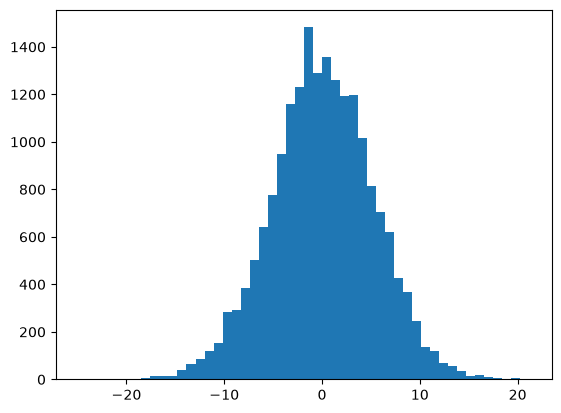

In [7]:

# experimental neural net

# not scaling init weights
Ctest = torch.randn((27, 10), generator=g)
W1test = torch.randn((30, 300), generator=g)
b1test = torch.randn(300, generator=g)
W2test = torch.randn((300, 27), generator=g)
b2test = torch.randn(27, generator=g)

parameterstest = (Ctest, W1test, b1test, W2test, b2test)

print(f"number of parameters = {sum(p.nelement() for p in parameterstest)}")

for p in parameterstest:
    p.requires_grad = True

# single forward and backward pass
ixtest = torch.randint(0, Xtr.shape[0], (64,), generator=g)

# forward pass
embtest = Ctest[Xtr[ixtest]]
htest = embtest.view(-1, 30) @ W1test + b1test
h1test = torch.tanh(htest)
logitstest = h1test @ W2test + b2test
losstest = F.cross_entropy(logitstest, Ytr[ixtest])

print(losstest)

# backward pass
for p in parameterstest:
    p.grad = None

losstest.backward()

plt.hist(htest.detach().view(-1).tolist(), 50)


(array([6624.,  610.,  352.,  242.,  165.,  133.,  145.,  100.,  107.,
          96.,   92.,   70.,   86.,   72.,   56.,   86.,   87.,   45.,
          64.,   63.,   54.,   52.,   42.,   49.,   59.,   59.,   40.,
          58.,   68.,   64.,   49.,   50.,   67.,   59.,   70.,   92.,
          66.,   81.,   74.,  117.,   94.,  123.,  102.,   94.,  134.,
         173.,  172.,  344.,  500., 6899.]),
 array([-1.  , -0.96, -0.92, -0.88, -0.84, -0.8 , -0.76, -0.72, -0.68,
        -0.64, -0.6 , -0.56, -0.52, -0.48, -0.44, -0.4 , -0.36, -0.32,
        -0.28, -0.24, -0.2 , -0.16, -0.12, -0.08, -0.04,  0.  ,  0.04,
         0.08,  0.12,  0.16,  0.2 ,  0.24,  0.28,  0.32,  0.36,  0.4 ,
         0.44,  0.48,  0.52,  0.56,  0.6 ,  0.64,  0.68,  0.72,  0.76,
         0.8 ,  0.84,  0.88,  0.92,  0.96,  1.  ]),
 <BarContainer object of 50 artists>)

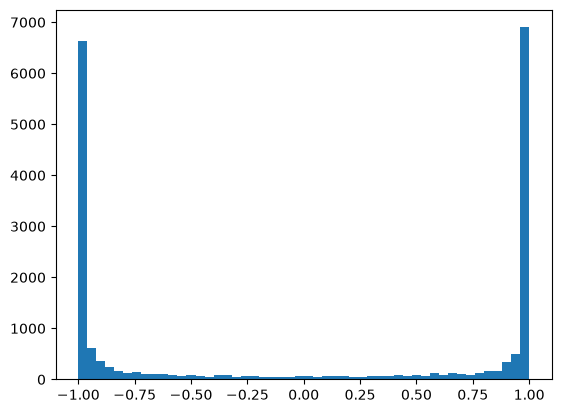

In [8]:
plt.hist(h1test.view(-1).tolist(), 50) # post activation

Text(0.5, 1.0, 'loss vs epoch graph')

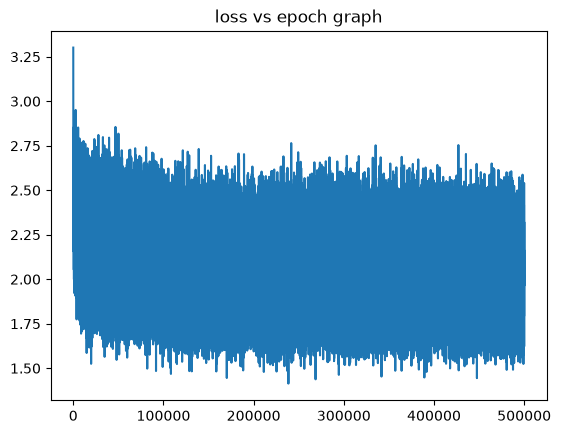

In [9]:
plt.plot(steps, losses)
plt.title("loss vs epoch graph")

#### inference
<small>

when running inference, we can clamp the mean and std of the whole dataset for batch norm during inference for more stable inference results. we can do it like this, but its kinda you know, redundant and theres no reason to do it like this. so we have a bn_runningmean and bn_runningstd which is updated not by gradient descent, but by smooth custom optimision with local bn mean and std. it is now added to the main training loop. the below cell is just for illustration.

</small>

In [10]:
# calibrate the batch mean and std over the whole training set for the hidden layer

'''

with torch.no_grad():
    emb = C[Xtr] # (32, 3, 2)
    h = (emb.view(-1, 30) @ W1 + b1) # (32, 100)

    # measure the mean and std over the whole set
    
    bnmean = h.mean(0, keepdim=True)
    bnstd = h.std(0, keepdim=True)

'''

'\n\nwith torch.no_grad():\n    emb = C[Xtr] # (32, 3, 2)\n    h = (emb.view(-1, 30) @ W1 + b1) # (32, 100)\n\n    # measure the mean and std over the whole set\n\n    bnmean = h.mean(0, keepdim=True)\n    bnstd = h.std(0, keepdim=True)\n\n'

In [11]:
# validation tests

with torch.no_grad():
    emb = C[Xtr] # (32, 3, 2)
    h = (emb.view(-1, 30) @ W1) # (32, 100)
    h = bngain*((h - bn_rmean)/bn_rstd) + bnbias
    h1 = torch.tanh(h)
    logits = h1 @ W2 + b2 # (32, 27)
    losstrain = F.cross_entropy(logits, Ytr)

    emb = C[Xdev] # (32, 3, 2)
    h = (emb.view(-1, 30) @ W1) # (32, 100)
    h = bngain*((h - bn_rmean)/bn_rstd) + bnbias
    h1 = torch.tanh(h)
    logits = h1 @ W2 + b2 # (32, 27)
    lossval = F.cross_entropy(logits, Ydev)

    # if nearly same, our network is underfitting. scaling up the model.
    print(f"training loss - {losstrain}\n validation loss - {lossval}")


training loss - 2.0069663524627686
 validation loss - 2.0873374938964844


#### sampling from the model
<small>

now we sample from the model as we used to before.

</small>

In [12]:
num_samples = 10
itos = {i:s for s,i in stoi.items()}

for i in range(num_samples):
    context = [0]*3
    out = []
    while True:
        emb = C[torch.tensor([context])]
        h = (emb.view(-1, 30) @ W1)
        h = bngain*((h - bn_rmean)/bn_rstd) + bnbias
        h1 = torch.tanh(h)
        logits = h1 @ W2 + b2 # (32, 27)

        probs = F.softmax(logits, dim = 1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        
        context = context[1:] + [ix]
        out.append(ix)
        if ix==0:
            break
    for i in out:
        print(itos[i], end = '')
    print()
    

kalesdaylo.
nacie.
faribubb.
loreey.
felin.
kyson.
lavier.
malic.
leona.
mic.


<small>

there are important things to consider when training neural nets. for example, visualizing the update:data ratio can actually signify how well we are converging in different epochs. we can log them to scale them to smaller values. it all comes down to graphing and intuition.

## picomake: loss history

### Results

| Commit | Change | Train loss | Val loss |
|---|---|---|---|
| `a764300` | Starter code, plain `randn` weights | 2.0847 | 2.1344 |
| `c9cf11c` | Tanh fix: `W1*0.1`, `W2*0.01`, zero biases | 1.9918 | 2.0943 |
| `5e45a93` | Kaiming init: `W1*(5/3)/√30` | 1.9918 (stale) | 2.0943 (stale) |
| `a2ac855` | Batch norm layer, `b1` removed | 2.0051 | 2.0813 |
| `98c4083` | Sampling only, no training change | 2.0051 | 2.0813 |

### Notes

- **Tanh fix (`c9cf11c`):** the biggest gain. Train loss dropped by about 0.093 and val by about 0.040. The step-0 loss was 3.2051, close to the ~3.3 expected from a uniform guess over 27 characters.
- **Kaiming init (`5e45a93`):** the outputs are identical to the previous commit down to the last digit, so they are stale. The init cell and the validation cell both have `execution_count: null`, meaning they were not re-run after the change. This step has no real measurement of its own; re-running the notebook would give one.
- **Batch norm (`a2ac855`):** train loss got slightly worse (1.9918 → 2.0051) but val improved (2.0943 → 2.0813). The train–val gap shrank from about 0.102 to 0.076. The step-0 loss was 3.2987.

</small>